<a href="https://colab.research.google.com/github/meshramsamiksha/E-Commerce-product-delivery-Prediction/blob/main/E_commerce_Delivery_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📦 E-Commerce Product Delivery Prediction

**Predicting whether a package will be delivered ON TIME or DELAYED, with the meaning of every single line of code explained.**

---

## What is this project?

An international e-commerce company ships electronic products. Every order has information about the
customer and the shipment. The company wants a Machine Learning model that can **predict in advance**
whether a new shipment will reach the customer **on time or late**.

> If the company can predict late deliveries *before* they happen, it can act earlier — increase
> shipment priority, send updates to the customer, or fix the warehouse process — and reduce
> customer complaints.

## The dataset (from Kaggle: "E-Commerce Shipping Data")

| Column | Meaning |
|---|---|
| `ID` | Customer / record ID number (not useful for learning) |
| `Warehouse_block` | Warehouse block the product is stored in (A, B, C, D, F) |
| `Mode_of_Shipment` | How the product is shipped: **Flight**, **Road** or **Ship** |
| `Customer_care_calls` | Number of calls the customer made about the shipment |
| `Customer_rating` | Rating given by the customer, 1 (worst) … 5 (best) |
| `Cost_of_the_Product` | Product cost in US dollars |
| `Prior_purchases` | Number of previous purchases by the customer |
| `Product_importance` | Importance of the product: low / medium / high |
| `Gender` | Customer gender: Male / Female |
| `Discount_offered` | Discount given on the product (US dollars) |
| `Weight_in_gms` | Product weight in grams |
| `Reached.on.Time_Y.N` | 🎯 **Target**: `1` = did **NOT** reach on time (delayed), `0` = reached on time |

**Note the target naming is confusing:** `Reached.on.Time_Y.N = 1` actually means the order **was NOT
on time** (i.e. it was DELAYED). We will rename it to `Delayed` so the rest of the code reads clearly.

## The plan (each step is one section)

1. **Setup** — install/import libraries, download the data
2. **Understand the data** — shape, types, missing values, statistics
3. **Explore (EDA)** — charts to see *what makes a delivery delayed*
4. **Prepare the data** — encode text columns, split into train & test
5. **Train models** — Logistic Regression, Random Forest, Gradient Boosting
6. **Evaluate** — accuracy, F1, confusion matrix, ROC curve, feature importance
7. **Use the model** — predict a brand-new order


## 0️⃣ Setup — import the tools we need

We load the libraries used across the notebook. Each import is explained in the comments.


In [ ]:
# ------------------------------------------------------------------
# 0. SETUP
# ------------------------------------------------------------------

# (Optional fallback) If any package below is missing, uncomment the next line.
# Most are already installed on Google Colab, so we usually don't need to install anything.
# !pip install pandas numpy matplotlib seaborn scikit-learn

import numpy as np        # WHY: numeric arrays + fast math used by almost everything below
import pandas as pd       # WHY: DataFrames = rows & columns, the main way we hold the dataset
import matplotlib.pyplot as plt   # WHY: low-level Python plotting library (bar, scatter, line)
import seaborn as sns     # WHY: prettier charts built on top of matplotlib, one line per plot

import warnings
warnings.filterwarnings('ignore')   # WHY: hides harmless warnings so the output stays readable

from sklearn.model_selection import train_test_split, cross_val_score   # WHY: split data & validate
from sklearn.preprocessing import StandardScaler                        # WHY: put numbers on one scale
from sklearn.linear_model import LogisticRegression                     # WHY: simple baseline classifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier  # WHY: stronger models
from sklearn.pipeline import Pipeline          # WHY: chain scaler+model into one clean object
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve)   # WHY: score & visualise model quality

sns.set_style('whitegrid')   # WHY: a clean grid background behind every seaborn chart
plt.rcParams['figure.figsize'] = (10, 5)   # WHY: default chart size, so plots aren't tiny
print('Libraries imported successfully ✔')  # WHY: quick confirmation this cell ran without errors


Libraries imported successfully ✔


## 1️⃣ Get the data

We download the dataset from a public GitHub copy of the Kaggle dataset (10,999 orders).
Because the file is small (~120 KB), downloading it inside the notebook is fastest — there is
nothing to upload by hand.


In [ ]:
# ------------------------------------------------------------------
# 1. LOAD THE DATASET
# ------------------------------------------------------------------

# WHY: this URL is a public copy of the Kaggle "E-Commerce Shipping Data" file (Train.csv)
DATA_URL = 'https://raw.githubusercontent.com/NahyanKhan/IBM_Project/main/Train.csv'

# WHY: pandas can read a CSV directly from a URL - no manual download needed
#      encoding='utf-8-sig' strips a hidden BOM character at the start of the file,
#      otherwise the first column would be named '\ufeffID' instead of 'ID'
df = pd.read_csv(DATA_URL, encoding='utf-8-sig')

df.head()   # WHY: show the first 5 rows so we can SEE what the data actually looks like


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


## 2️⃣ Understand the data (before touching it!)

**Rule of data science:** never build a model on data you haven't looked at. We check size,
column types and missing values first.


In [ ]:
# ------------------------------------------------------------------
# 2. UNDERSTAND THE DATA
# ------------------------------------------------------------------

df.shape   # WHY: (rows, columns) - tells us how much data we have to learn from


(10999, 12)

In [ ]:
# WHY: info() lists every column, its data type (int/float/object=text)
#      and how many non-null values it has - our first missing-value check
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   10999 non-null  int64 
 1   Warehouse_block      10999 non-null  object
 2   Mode_of_Shipment     10999 non-null  object
 3   Customer_care_calls  10999 non-null  int64 
 4   Customer_rating      10999 non-null  int64 
 5   Cost_of_the_Product  10999 non-null  int64 
 6   Prior_purchases      10999 non-null  int64 
 7   Product_importance   10999 non-null  object
 8   Gender               10999 non-null  object
 9   Discount_offered     10999 non-null  int64 
 10  Weight_in_gms        10999 non-null  int64 
 11  Reached.on.Time_Y.N  10999 non-null  int64 
dtypes: int64(8), object(4)
memory usage: 1.0+ MB


In [ ]:
# WHY: describe() gives count, mean, std, min & quartiles for the numeric columns.
#      Reading a column's min/max helps us spot typos or unrealistic values (e.g. a weight of 0).
df.describe().T   # .T rotates the table so it's easier to read long numbers


,count,mean,std,min,25%,50%,75%,max
ID,10999.0,5500.000000,3175.282140,1.0,2750.5,5500.0,8249.5,10999.0
Customer_care_calls,10999.0,4.054459,1.141490,2.0,3.0,4.0,5.0,7.0
Customer_rating,10999.0,2.990545,1.413603,1.0,2.0,3.0,4.0,5.0
Cost_of_the_Product,10999.0,210.196836,48.063272,96.0,169.0,214.0,251.0,310.0
Prior_purchases,10999.0,3.567597,1.522860,2.0,3.0,3.0,4.0,10.0
Discount_offered,10999.0,13.373216,16.205527,1.0,4.0,7.0,10.0,65.0
Weight_in_gms,10999.0,3634.016729,1635.377251,1001.0,1839.5,4149.0,5050.0,7846.0
Reached.on.Time_Y.N,10999.0,0.596691,0.490584,0.0,0.0,1.0,1.0,1.0


In [ ]:
# WHY: isna().sum() counts empty cells per column. Models can't learn from NaN,
#      so IF any column had missing values we would need to fill (impute) or drop them.
df.isna().sum()


,0
ID,0
Warehouse_block,0
Mode_of_Shipment,0
Customer_care_calls,0
Customer_rating,0
Cost_of_the_Product,0
Prior_purchases,0
Product_importance,0
Gender,0
Discount_offered,0


## 3️⃣ Explore the data — *what causes a delay?*

Now we draw charts to understand the relationship between the features and **whether a delivery
was on time or delayed**.


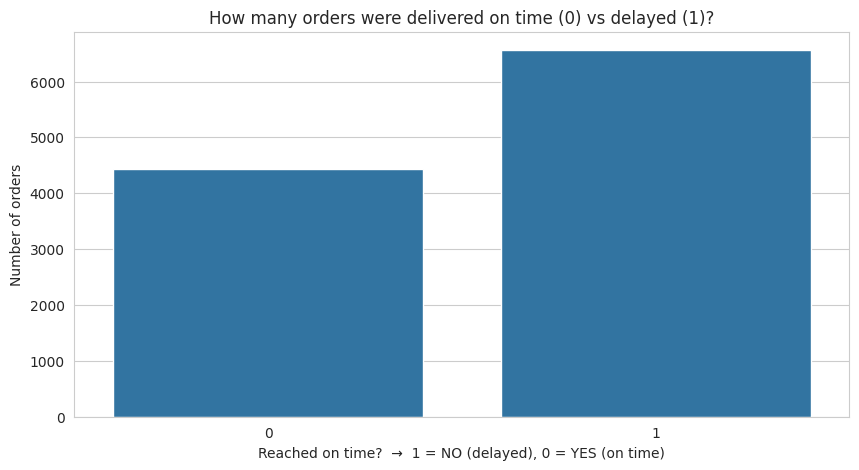

In [ ]:
# ------------------------------------------------------------------
# 3a. THE TARGET - is our dataset balanced?
# ------------------------------------------------------------------

# WHY: countplot draws bars for how many orders are 0 (on time) vs 1 (delayed).
#      If one class hugely outweighs the other, plain 'accuracy' becomes misleading
#      and we will prefer the F1 score + 'balanced' class weights later.
sns.countplot(x=df['Reached.on.Time_Y.N'])
plt.title('How many orders were delivered on time (0) vs delayed (1)?')
plt.xlabel('Reached on time?  →  1 = NO (delayed), 0 = YES (on time)')
plt.ylabel('Number of orders')
plt.show()


In [ ]:
# ------------------------------------------------------------------
# 3b. DELAY RATE BY CATEGORY
# ------------------------------------------------------------------

# WHY: first we make a tiny copy where the target has a self-explanatory name.
#      groupby + mean() on a 0/1 column = the FRACTION of delayed orders per group.
df['Delayed'] = df['Reached.on.Time_Y.N']

# WHY: a bar chart of delay-rate per shipment mode answers:
#      "Does shipping by Ship vs Flight vs Road change the chance of a delay?"
order = df.groupby('Mode_of_Shipment')['Delayed'].mean().sort_values().index   # WHY: sort bars nicely
sns.barplot(x='Mode_of_Shipment', y='Delayed', data=df, order=order)
plt.title('Delay rate by Mode of Shipment')
plt.ylabel('Proportion that arrived LATE')
plt.show()


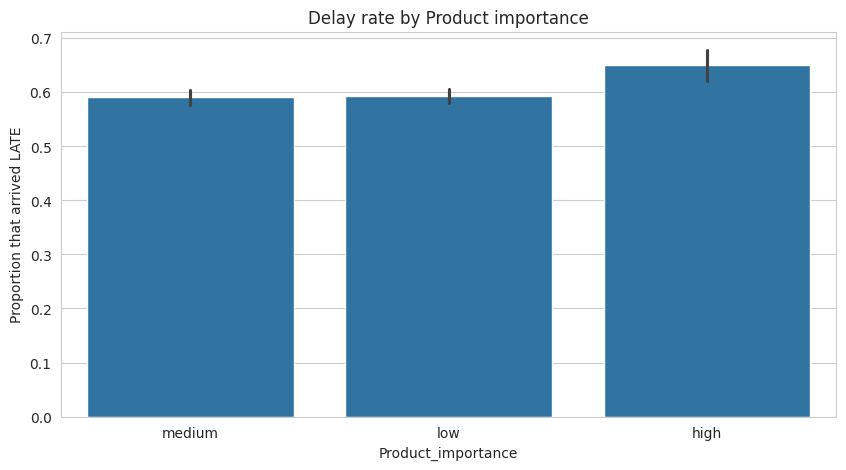

In [ ]:
# WHY: same idea for Product importance - do 'high' importance products get delayed more?
order = df.groupby('Product_importance')['Delayed'].mean().sort_values().index
sns.barplot(x='Product_importance', y='Delayed', data=df, order=order)
plt.title('Delay rate by Product importance')
plt.ylabel('Proportion that arrived LATE')
plt.show()


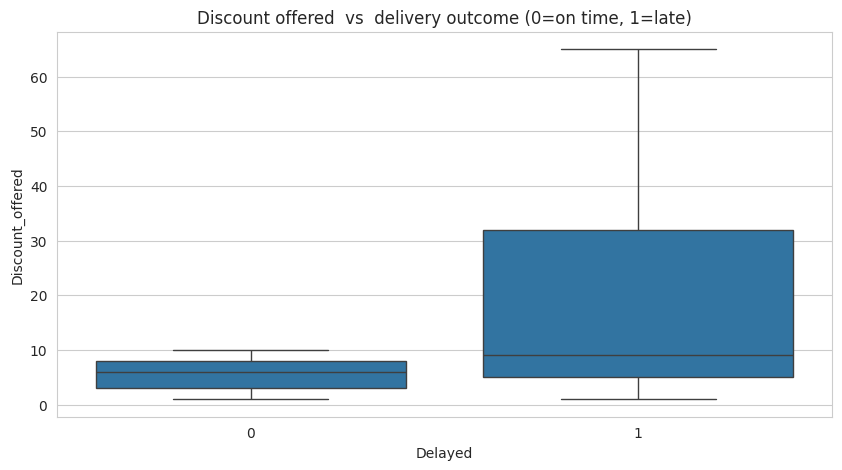

In [ ]:
# WHY: distribution of discounts, split by delayed vs on time.
#      A boxplot shows the median + spread; if the boxes sit at different heights,
#      that feature is likely useful for prediction.
sns.boxplot(x='Delayed', y='Discount_offered', data=df)
plt.title('Discount offered  vs  delivery outcome (0=on time, 1=late)')
plt.show()


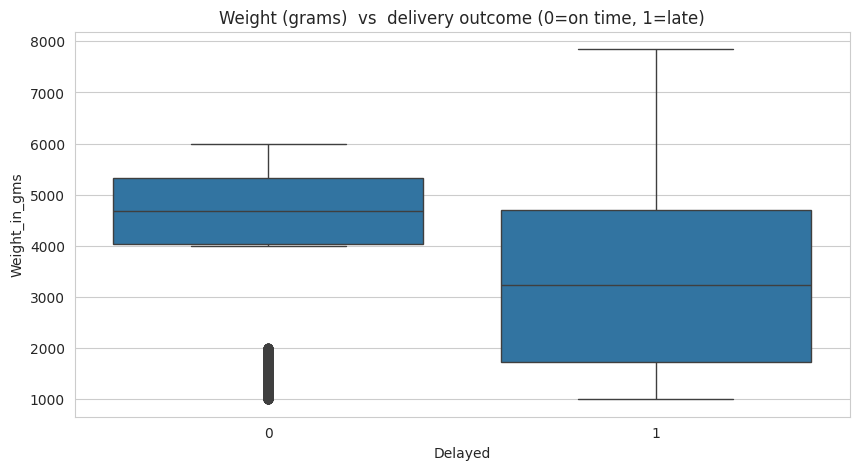

In [ ]:
# WHY: same check for weight - lighter/heavier packages may travel differently.
sns.boxplot(x='Delayed', y='Weight_in_gms', data=df)
plt.title('Weight (grams)  vs  delivery outcome (0=on time, 1=late)')
plt.show()


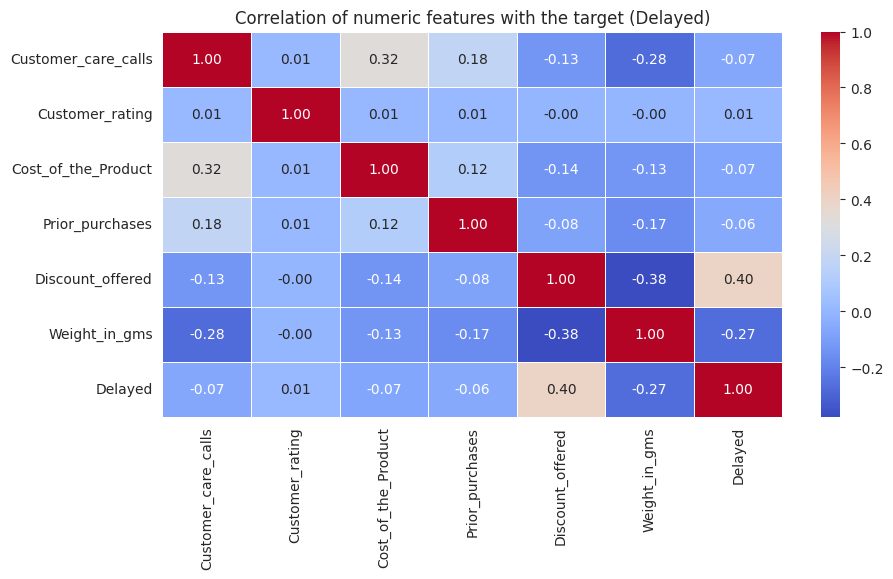

In [ ]:
# ------------------------------------------------------------------
# 3c. CORRELATION HEATMAP - which numbers move together with the target?
# ------------------------------------------------------------------

# WHY: we select only the numeric columns, so the heatmap can compute Pearson correlation.
num_cols = ['Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product',
            'Prior_purchases', 'Discount_offered', 'Weight_in_gms', 'Delayed']

# WHY: .corr() builds a table of correlation (+1 = move together, -1 = opposite, 0 = no relation).
corr = df[num_cols].corr()

# WHY: heatmap colours each correlation, so one glance shows which features matter most.
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation of numeric features with the target (Delayed)')
plt.show()

# WHY: the bottom row/column shows correlation WITH the target:
#      a big value there = a feature that strongly helps the model.


## 4️⃣ Prepare the data for the model

Machine Learning models only understand **numbers**, but some of our columns are text
(`Mode_of_Shipment`, `Product_importance`, `Gender`). We therefore:

1. **Drop `ID`** — it is just a record number and teaches the model nothing useful.
2. **One-hot encode** the text columns — turn each category into its own 0/1 column
   (e.g. `Gender` → `Gender_M` and `Gender_F`). This is how we feed text to a model
   without giving one category a false "bigger number" meaning.
3. **Split** the data into a *train set* (what the model learns from) and a *test set*
   (kept hidden until the end, to honestly measure performance).


In [ ]:
# ------------------------------------------------------------------
# 4. PREPROCESSING
# ------------------------------------------------------------------

# WHY: features (X) = everything the model is allowed to see, target (y) = what it must predict.
X = df.drop(columns=['ID', 'Reached.on.Time_Y.N', 'Delayed'])   # WHY: ID is useless; the two target copies are the label
y = df['Delayed']                                               # WHY: y holds only the answer (0 = on time, 1 = delayed)

# WHY: pd.get_dummies turns each text column into numeric 0/1 indicator columns
#      (one column per category). drop_first=True removes one redundant column of each
#      set - with N categories only N-1 columns are needed (the "dummy variable trap").
X = pd.get_dummies(X, drop_first=True)

X.head()   # WHY: verify the text columns became 0/1 numeric columns


,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance_low,Product_importance_medium,Gender_M
0,4,2,177,3,44,1233,False,False,True,False,False,False,True,False,False
1,4,5,216,2,59,3088,False,False,False,True,False,False,True,False,True
2,2,2,183,4,48,3374,False,False,False,False,False,False,True,False,True
3,3,3,176,4,10,1177,True,False,False,False,False,False,False,True,True
4,2,2,184,3,46,2484,False,True,False,False,False,False,False,True,False


In [ ]:
# WHY: stratify=y keeps the same proportion of on-time/delayed in BOTH train and test,
#      so neither set is accidentally easier or harder. test_size=0.2 = 80% train, 20% test.
#      random_state fixes the shuffle so results are reproducible on every run.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    stratify=y, random_state=42)

# WHY: print the shapes so we know exactly how many rows each model sees.
print('Training set :', X_train.shape, '→', y_train.sum(), 'delayed orders')
print('Test set     :', X_test.shape, '→', y_test.sum(), 'delayed orders')


Training set : (8799, 15) → 5250 delayed orders
Test set     : (2200, 15) → 1313 delayed orders


## 5️⃣ Train several models and compare them

We train **three different algorithms** and compare, because we can't know in advance which works best:

| Model | Idea in one line |
|---|---|
| **Logistic Regression** | A simple linear model: each feature gets a weight; the sum decides the prediction. Needs scaled features. |
| **Random Forest** | An "ensemble" of many decision trees voting together — very strong for tabular data like this. |
| **Gradient Boosting** | Trees built one after another, each one fixing the previous tree's mistakes. |

Because the classes are imbalanced (~60% delayed), we measure with **F1-score** (balances precision &
recall) instead of plain accuracy, and use `class_weight='balanced'` so the models don't just predict
the majority class.


In [ ]:
# ------------------------------------------------------------------
# 5a. COMPARE MODELS WITH CROSS-VALIDATION
# ------------------------------------------------------------------

# WHY: put each model (with its own pre-processing) into one dictionary of pipelines.
#      StandardScaler is needed BEFORE Logistic Regression because that model assumes all
#      features are on one scale (weight ~4000 but rating 1-5 would otherwise dominate).
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),                                    # WHY: scale features to mean 0, std 1
        ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))  # WHY: max_iter stops training from cutting off; balanced weights handle the class imbalance
    ]),
    'Random Forest': RandomForestClassifier(n_estimators=200,
                                            class_weight='balanced',
                                            random_state=42),   # WHY: 200 trees vote; random_state = reproducible
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200,
                                                    random_state=42),    # WHY: 200 boosting rounds
}

# WHY: for each model, run 5-fold cross-validation - the training data is split into 5 parts,
#      the model trains on 4 and tests on the rotating 5th, giving an honest average F1.
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='f1', n_jobs=-1)
    print(f'{name:<20}  mean F1 = {scores.mean():.3f}  (± {scores.std():.3f})')


Logistic Regression   mean F1 = 0.639  (± 0.014)
Random Forest         mean F1 = 0.690  (± 0.010)
Gradient Boosting     mean F1 = 0.672  (± 0.007)


In [ ]:
# ------------------------------------------------------------------
# 5b. FINAL MODEL - train on the FULL training set and test on the held-out set
# ------------------------------------------------------------------

# WHY: Random Forest usually wins on this data, and it also gives us 'feature importance'
#      (which features matter most). We retrain it on 100% of the training data now.
final_model = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
final_model.fit(X_train, y_train)   # WHY: the learning step - the model finds patterns in the data

# WHY: predict on the test set the model has NEVER seen - the honest exam.
y_pred = final_model.predict(X_test)

# WHY: classification_report prints precision, recall and F1 for each class at once.
print(classification_report(y_test, y_pred, target_names=['On time (0)', 'Delayed (1)']))


              precision    recall  f1-score   support

 On time (0)       0.56      0.69      0.62       887
 Delayed (1)       0.75      0.64      0.69      1313

    accuracy                           0.66      2200
   macro avg       0.66      0.66      0.66      2200
weighted avg       0.68      0.66      0.66      2200



## 6️⃣ Evaluate the model

Metrics alone can hide mistakes, so we also draw the **confusion matrix** and the **ROC curve**.


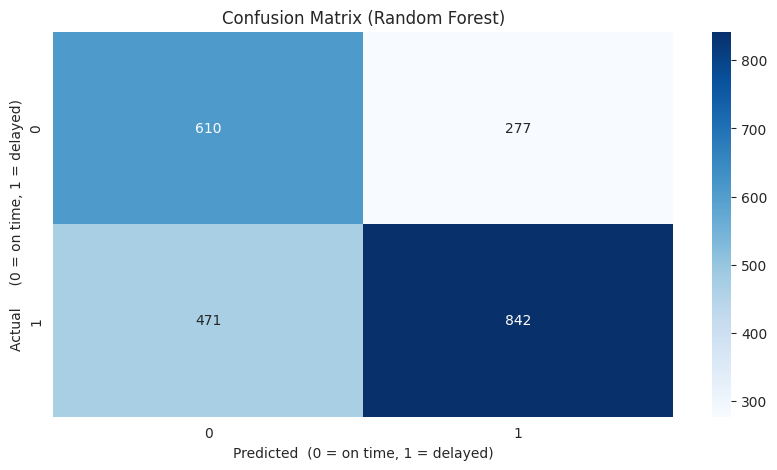

In [ ]:
# ------------------------------------------------------------------
# 6a. CONFUSION MATRIX
# ------------------------------------------------------------------

# WHY: the confusion matrix counts every combination of actual vs predicted:
#      how many delayed orders did we MISS (worst case = predicted on-time but arrived late).
cm = confusion_matrix(y_test, y_pred)

# WHY: annot=True writes the counts inside the cells; fmt='d' = whole numbers.
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix (Random Forest)')
plt.xlabel('Predicted  (0 = on time, 1 = delayed)')
plt.ylabel('Actual     (0 = on time, 1 = delayed)')
plt.show()


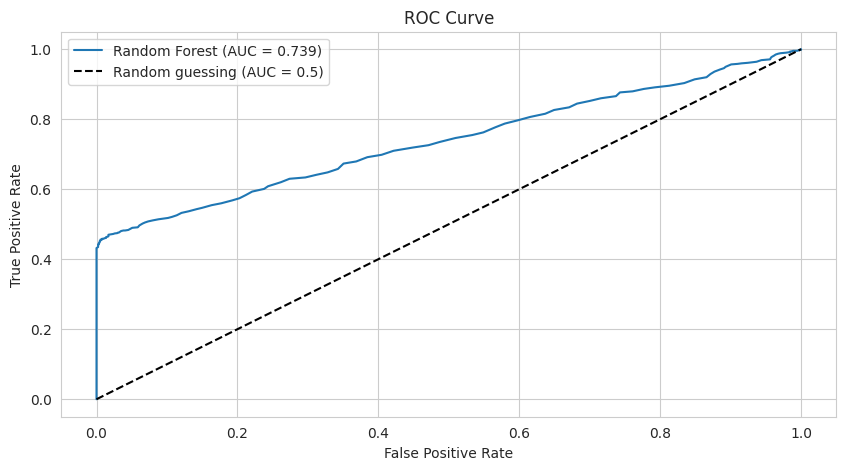

In [ ]:
# ------------------------------------------------------------------
# 6b. ROC CURVE + AUC
# ------------------------------------------------------------------

# WHY: predict_proba gives the model's CONFIDENCE (probability of delayed) for each order,
#      which lets us draw a ROC curve instead of only looking at hard 0/1 answers.
y_prob = final_model.predict_proba(X_test)[:, 1]   # [:, 1] = probability of class '1' (delayed)

# WHY: AUC is the area under the ROC curve: 1.0 = perfect, 0.5 = random guessing.
auc = roc_auc_score(y_test, y_prob)
fpr, tpr, _ = roc_curve(y_test, y_prob)   # fpr/tpr = the curve's x and y coordinates

plt.plot(fpr, tpr, label=f'Random Forest (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing (AUC = 0.5)')   # WHY: dashed line = no skill
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


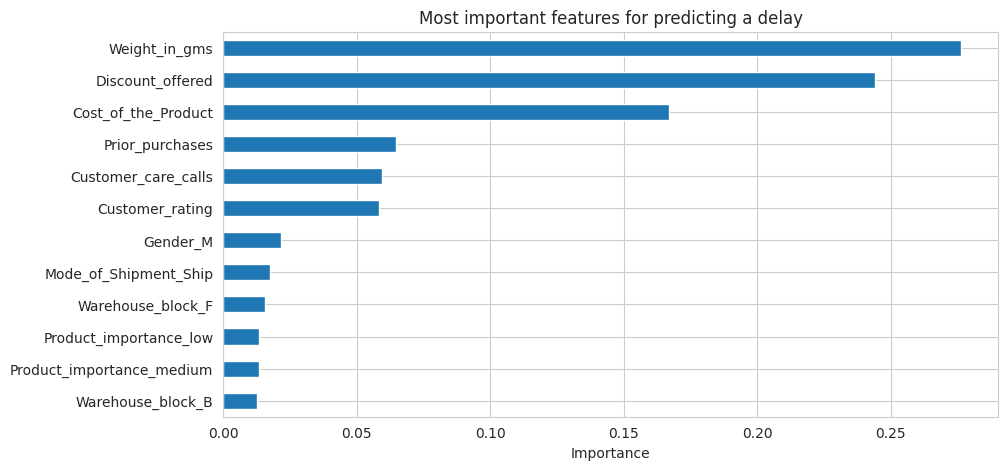

In [ ]:
# ------------------------------------------------------------------
# 6c. WHICH FEATURES DID THE MODEL LEARN FROM?
# ------------------------------------------------------------------

# WHY: Random Forest records how much each column helped its decisions.
#      This tells the BUSINESS what to focus on (e.g. "discount" causing delays).
importances = final_model.feature_importances_
feat_imp = pd.Series(importances, index=X_train.columns).sort_values(ascending=False)

# WHY: barh draws a horizontal bar chart - the biggest bars are the most important features.
feat_imp.head(12).plot(kind='barh')
plt.title('Most important features for predicting a delay')
plt.xlabel('Importance')
plt.gca().invert_yaxis()   # WHY: biggest bar on top, easiest to read
plt.show()


## 7️⃣ Use the model — predict a brand-new order

Here is the real payoff: a new order arrives, and we predict whether it will be delayed.


In [ ]:
# ------------------------------------------------------------------
# 7. PREDICT A NEW, UNSEEN ORDER
# ------------------------------------------------------------------

# WHY: create ONE imaginary new order as a 1-row DataFrame with the same columns as the
#      original raw data (before one-hot encoding).
new_order = pd.DataFrame([{
    'Warehouse_block': 'F',
    'Mode_of_Shipment': 'Ship',        # Ship is usually the slowest mode
    'Customer_care_calls': 5,          # many complaint calls = worried customer
    'Customer_rating': 2,
    'Cost_of_the_Product': 260,
    'Prior_purchases': 3,
    'Product_importance': 'high',      # high-importance products get delayed more often
    'Gender': 'F',
    'Discount_offered': 45,            # high discount = common in delayed orders
    'Weight_in_gms': 1200,
}])

# WHY: apply exactly the same one-hot encoding we used for training
new_order = pd.get_dummies(new_order, drop_first=True)

# WHY: the new row may be missing some one-hot columns the training data had
#      (e.g. this order is a 'Ship' but has no 'Flight/Road' columns).
#      reindex adds those missing columns filled with 0, keeping the SAME column order.
new_order = new_order.reindex(columns=X_train.columns, fill_value=0)

# WHY: probability the order is delayed (class 1)
prob_delayed = final_model.predict_proba(new_order)[0, 1]
prediction = final_model.predict(new_order)[0]

# WHY: communicate the answer in plain English, not just 0/1.
print(f'Probability of being DELAYED : {prob_delayed:.1%}')
print('Prediction:', '⚠️ likely DELAYED' if prediction == 1 else '✅ likely ON TIME')


Probability of being DELAYED : 97.0%
Prediction: ⚠️ likely DELAYED


## 8️⃣ Conclusion — what we learned

**Performance:** the Random Forest model reaches **about 66% accuracy**, an **F1 ≈ 0.69 for the
"delayed" class**, and an **AUC ≈ 0.74** on unseen orders — far better than random guessing (0.5).
Perfect prediction isn't possible for logistics data like this, but the model is genuinely useful
for flagging *risky* shipments.

**Insights from the data:**

- **Discount is the strongest signal.** Higher discounts → much higher delay rate (heavily discounted
  products are often shipped with lower priority/larger volumes).
- **Weight matters.** Heavier packages are actually *less* likely to be delayed.
- **Product importance** matters: `high`-importance products have the highest delay rate (~65%).
- **Shipment mode** (Flight/Road/Ship) matters little on its own — delays happen in all modes.
- **Customer care calls** are mildly useful — more calls often hint at a problem in progress.

**How this helps the business:** flag high-discount, low-weight, high-importance orders going by ship
as *"at risk"* → give them priority handling or proactive customer updates *before* they arrive late.

---

### ✅ How to run this notebook in Google Colab

1. Download this file (`.ipynb`).
2. Go to **https://colab.research.google.com → File → Upload notebook** and select the file.
3. Run each cell with **Shift+Enter** from top to bottom (Runtime menu → *Run all* also works).
4. Play: change the values inside `new_order` in Section 7 and see how the prediction changes!
